<a href="https://colab.research.google.com/github/teacher-michael/datos_diplomado_IA/blob/main/05_EDA_con_datos_economicosB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05. Análisis exploratorio y pruebas estadísticas

**Curso:** Análisis de datos para la investigación con Python

**Propósito:** Explorar datos económicos del Banco Mundial, reconocer distribuciones y relaciones, y aplicar pruebas básicas sin confundir significancia con importancia o causalidad.

**Ruta:** calidad → univariado → bivariado → normalidad → asociación → serie temporal

Este cuaderno está pensado para una clase virtual demostrativa. Primero se explica la idea, luego se observa el código y, después de varios ejemplos, aparece una pausa práctica.

## Cómo trabajar en Google Colab

1. Guarda una copia del notebook en tu Drive.
2. Ejecuta en orden con el botón de reproducción o con `Shift + Enter`.
3. Una celda de texto explica y una celda de código ejecuta instrucciones.
4. Si reinicias el entorno, usa **Entorno de ejecución → Ejecutar todas**.
5. En las pausas prácticas modifica la celda marcada y luego compara con la solución.

Un error no daña el computador. Lee la última línea del mensaje y revisa nombres, mayúsculas, comillas, paréntesis e indentación.

## Pregunta orientadora

**¿Qué patrones y diferencias aparecen entre países al comparar conectividad, ingreso, desempleo e inflación?**

El EDA ayuda a comprender cobertura, forma, valores extremos y relaciones antes de elegir un modelo. También puede generar preguntas nuevas. No confirma causalidad ni sustituye el diseño de investigación.

## 1. Variables y unidades

Trabajaremos con:

- personas que usan Internet (% de la población);
- PIB per cápita (USD corrientes);
- desempleo (% de la fuerza laboral);
- inflación anual (%);
- esperanza de vida (años);
- población total (personas).

Mezclar escalas sin reconocerlas produce gráficos y modelos difíciles de interpretar.

In [1]:
import sys
import subprocess
import importlib.util

# Instalamos solo las dependencias que aún no existen en el entorno.
for paquete in ["wbgapi", "seaborn", "plotly", "geopandas", "folium", "pyproj"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import geopandas as gpd
import folium
import wbgapi as wb
from scipy import stats
from pyproj import Geod
from branca.colormap import linear
from html import escape

pd.set_option("display.max_columns", 30)
print("Entorno preparado")

# Cada respuesta puede traer más filas: reducimos el número de consultas al servidor.
wb.per_page = 10000
# Limitamos la espera para poder continuar con el respaldo si el servicio no responde.
wb.get_options["timeout"] = (15, 45)

Entorno preparado


## 2. Descargar un panel país-año con `wbgapi`

Un panel contiene varias unidades observadas en varios momentos. Solicitaremos 2018–2024.

En el notebook 4 usamos `wbgapi` para un indicador. Aquí aplicamos exactamente la misma idea a seis indicadores. La librería sigue consultando la API del Banco Mundial, pero evita escribir direcciones, parámetros, páginas y ciclos sobre respuestas JSON.

In [2]:
# Cada nombre corto será una columna fácil de interpretar.
indicadores = {
    "internet": "IT.NET.USER.ZS",
    "pib_per_capita": "NY.GDP.PCAP.CD",
    "desempleo": "SL.UEM.TOTL.ZS",
    "inflacion": "FP.CPI.TOTL.ZG",
    "esperanza_vida": "SP.DYN.LE00.IN",
    "poblacion": "SP.POP.TOTL",
}

datos_wb = None
try:
    # Una sola instrucción solicita países, años e indicadores.
    datos_wb = wb.data.DataFrame(
        list(indicadores.values()),
        economy="all",
        # range excluye su límite final: pedimos 2018 a 2024 inclusive.
        time=range(2018, 2025),
        # País y año identifican cada fila; los indicadores se convierten en columnas.
        index=["economy", "time"],
        columns="series",
        labels=True,
        # Excluimos agregados como Mundo para trabajar con economías individuales.
        skipAggs=True,
        numericTimeKeys=True,
    ).reset_index()
    print("Consulta completada con wbgapi")
except Exception as error:
    print("No fue posible actualizar con wbgapi:", type(error).__name__)

Consulta completada con wbgapi


La tabla descargada conserva los códigos originales de los indicadores. El siguiente bloque solo cambia nombres y ordena columnas; no modifica los valores.

In [3]:
nombres_columnas = {
    codigo: nombre
    for nombre, codigo in indicadores.items()
}

# Si la consulta respondió, traducimos y ordenamos sus columnas.
if datos_wb is not None:
    panel_mundial = (
        datos_wb
        .rename(columns={
            "economy": "codigo_pais",
            "Country": "pais",
            "time": "anio",
            # ** incorpora las equivalencias entre códigos del Banco Mundial y nombres cortos.
            **nombres_columnas,
        })
        .drop(columns=["Time"], errors="ignore")
    )
    panel_mundial["anio"] = panel_mundial["anio"].astype(int)
    panel_mundial = panel_mundial[
        ["codigo_pais", "pais", "anio"] + list(indicadores)
    ]
    # Guardamos el panel descargado para poder repetir la clase sin conexión.
    panel_mundial.to_csv("datos_banco_mundial_2018_2024.csv", index=False, encoding="utf-8-sig")
    print("Se usan datos actualizados del Banco Mundial")
else:
    # El respaldo permite continuar la clase si falla Internet.
    panel_mundial = pd.read_csv("datos_banco_mundial_2018_2024.csv")
    print("Se usó la copia local de respaldo")

print("Forma del panel:", panel_mundial.shape)
panel_mundial.head()

Se usan datos actualizados del Banco Mundial
Forma del panel: (1519, 9)


,codigo_pais,pais,anio,internet,pib_per_capita,desempleo,inflacion,esperanza_vida,poblacion
0,ZWE,Zimbabwe,2024,41.642799,2496.155150,9.435,NaN,63.064,16634373.0
1,ZWE,Zimbabwe,2023,38.674801,2195.225020,9.348,NaN,62.775,16340822.0
2,ZWE,Zimbabwe,2022,36.256500,2536.401971,10.087,104.705171,62.360,16069056.0
3,ZWE,Zimbabwe,2021,32.592400,2613.616741,9.540,98.546105,60.135,15797210.0
4,ZWE,Zimbabwe,2020,29.298565,2059.637040,8.617,557.201817,61.530,15526888.0


El respaldo conserva una fecha de consulta. No reemplaza una actualización cuando el periodo de investigación exige información nueva, pero permite continuar una clase ante una interrupción.

## 3. Añadir región, nivel de ingreso y coordenadas

`wb.economy.DataFrame()` consulta las fichas de economías. `skipAggs=True` excluye agregados como “Mundo”. Conservamos región, ingreso, capital y coordenadas para retomar la representación geográfica al final.

In [4]:
try:
    metadatos_paises = (
        wb.economy.DataFrame(skipAggs=True, labels=True)
        .reset_index()
        .rename(columns={"id": "codigo_pais", "incomeLevel": "nivel_ingreso"})
        [["codigo_pais", "region", "nivel_ingreso", "capitalCity", "longitude", "latitude"]]
    )
    # Conservamos también las coordenadas para que el cierre espacial tenga respaldo.
    metadatos_paises.to_csv("metadatos_banco_mundial.csv", index=False, encoding="utf-8-sig")
    print("Metadatos actualizados con wbgapi")
except Exception as error:
    print("Se usan metadatos de respaldo:", type(error).__name__)
    metadatos_paises = pd.read_csv("metadatos_banco_mundial.csv")

# Un respaldo antiguo puede no incluir coordenadas; las dejamos como faltantes.
for columna in ["capitalCity", "longitude", "latitude"]:
    if columna not in metadatos_paises:
        metadatos_paises[columna] = np.nan
# Las coordenadas pueden llegar como texto; GeoPandas necesita valores numéricos.
for columna in ["longitude", "latitude"]:
    metadatos_paises[columna] = pd.to_numeric(metadatos_paises[columna], errors="coerce")
metadatos_paises.head()

Metadatos actualizados con wbgapi


,codigo_pais,region,nivel_ingreso,capitalCity,longitude,latitude
0,ABW,Latin America & Caribbean,High income,Oranjestad,-70.0167,12.51670
1,AFG,"Middle East, North Africa, Afghanistan & Pakistan",Low income,Kabul,69.1761,34.52280
2,AGO,Sub-Saharan Africa,Lower middle income,Luanda,13.2420,-8.81155
3,ALB,Europe & Central Asia,Upper middle income,Tirane,19.8172,41.33170
4,AND,Europe & Central Asia,High income,Andorra la Vella,1.5218,42.50750


Integramos cada fila país-año con una sola ficha de país. `validate="many_to_one"` comprueba esa relación: muchas observaciones temporales pueden corresponder a un país, pero cada código debe tener un único registro de metadatos.

In [5]:
panel_paises = panel_mundial.merge(
    metadatos_paises,
    on="codigo_pais",
    how="inner",
    validate="many_to_one"
)
print(panel_paises.shape)
panel_paises.head()

(1519, 14)


,codigo_pais,pais,anio,internet,pib_per_capita,desempleo,inflacion,esperanza_vida,poblacion,region,nivel_ingreso,capitalCity,longitude,latitude
0,ZWE,Zimbabwe,2024,41.642799,2496.155150,9.435,NaN,63.064,16634373.0,Sub-Saharan Africa,Lower middle income,Harare,31.0672,-17.8312
1,ZWE,Zimbabwe,2023,38.674801,2195.225020,9.348,NaN,62.775,16340822.0,Sub-Saharan Africa,Lower middle income,Harare,31.0672,-17.8312
2,ZWE,Zimbabwe,2022,36.256500,2536.401971,10.087,104.705171,62.360,16069056.0,Sub-Saharan Africa,Lower middle income,Harare,31.0672,-17.8312
3,ZWE,Zimbabwe,2021,32.592400,2613.616741,9.540,98.546105,60.135,15797210.0,Sub-Saharan Africa,Lower middle income,Harare,31.0672,-17.8312
4,ZWE,Zimbabwe,2020,29.298565,2059.637040,8.617,557.201817,61.530,15526888.0,Sub-Saharan Africa,Lower middle income,Harare,31.0672,-17.8312


Trabajamos con una selección explícita de 22 países de América Latina y el Caribe. Incluimos Venezuela, Haití, Guyana y Suriname. Antes del análisis revisaremos la disponibilidad de Internet en 2024 para establecer el conjunto que utilizaremos durante el resto del cuaderno.

In [6]:
codigos_latam = [
    "ARG", "BOL", "BRA", "CHL", "COL", "CRI", "CUB", "DOM",
    "ECU", "GTM", "HND", "MEX", "NIC", "PAN", "PRY", "PER",
    "SLV", "URY", "VEN", "HTI", "GUY", "SUR"
]
panel_latam = panel_paises[
    panel_paises["codigo_pais"].isin(codigos_latam)
].copy()
print("Países de la selección inicial:", panel_latam["codigo_pais"].nunique())
print("Años:", sorted(panel_latam["anio"].unique()))

Países de la selección inicial: 22
Años: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]


### Pausa práctica: filtrar un país

**Tiempo sugerido: 3–5 minutos.** Selecciona las observaciones de Colombia y ordénalas por año.

In [ ]:
# Parte de panel_latam

### Respuesta sugerida

In [7]:
colombia = panel_latam[panel_latam["codigo_pais"].eq("COL")].sort_values("anio")
colombia

,codigo_pais,pais,anio,internet,pib_per_capita,desempleo,inflacion,esperanza_vida,poblacion,region,nivel_ingreso,capitalCity,longitude,latitude
1224,COL,Colombia,2018,64.126377,6816.968183,9.360,3.240569,76.579,49024465.0,Latin America & Caribbean,Upper middle income,Bogota,-74.082,4.60987
1223,COL,Colombia,2019,65.006901,6472.545449,10.280,3.523019,76.793,49907985.0,Latin America & Caribbean,Upper middle income,Bogota,-74.082,4.60987
1222,COL,Colombia,2020,69.795335,5339.687114,15.983,2.526635,74.757,50629997.0,Latin America & Caribbean,Upper middle income,Bogota,-74.082,4.60987
1221,COL,Colombia,2021,73.028374,6222.621644,13.898,3.495058,72.698,51188173.0,Latin America & Caribbean,Upper middle income,Bogota,-74.082,4.60987
1220,COL,Colombia,2022,72.796379,6680.445069,10.541,10.177231,76.508,51737944.0,Latin America & Caribbean,Upper middle income,Bogota,-74.082,4.60987
1219,COL,Colombia,2023,77.336863,7012.491691,9.591,11.735904,77.725,52321152.0,Latin America & Caribbean,Upper middle income,Bogota,-74.082,4.60987
1218,COL,Colombia,2024,79.345433,7951.086240,9.619,6.609086,77.913,52886363.0,Latin America & Caribbean,Upper middle income,Bogota,-74.082,4.60987


## 4. Tipos de variables

- `pais`, `region` y `nivel_ingreso` son categóricas nominales;
- `anio` es temporal discreta;
- porcentajes y magnitudes monetarias son cuantitativas;
- `codigo_pais` es identificador, no una cantidad.

El tipo estadístico depende del significado, no solo del tipo que muestra Python.

In [8]:
panel_latam.dtypes

,0
codigo_pais,object
pais,object
anio,int64
internet,float64
pib_per_capita,float64
desempleo,float64
inflacion,float64
esperanza_vida,float64
poblacion,float64
region,object


## 5. Cobertura y faltantes

Un valor faltante puede significar ausencia de reporte, demora, incompatibilidad o falta de aplicabilidad. Contaremos cobertura por variable y año.

In [9]:
variables_numericas = [
    "internet", "pib_per_capita", "desempleo",
    "inflacion", "esperanza_vida", "poblacion"
]
# Contamos valores presentes y faltantes antes de interpretar medidas o gráficos.
cobertura = panel_latam[variables_numericas].notna().sum()
faltantes = panel_latam[variables_numericas].isna().sum()
resumen_cobertura = pd.DataFrame({
    "observaciones_disponibles": cobertura,
    "faltantes": faltantes,
    "porcentaje_disponible": (cobertura / len(panel_latam) * 100).round(1)
})
resumen_cobertura

,observaciones_disponibles,faltantes,porcentaje_disponible
internet,149,5,96.8
pib_per_capita,150,4,97.4
desempleo,154,0,100.0
inflacion,138,16,89.6
esperanza_vida,154,0,100.0
poblacion,154,0,100.0


In [10]:
cobertura_por_anio = (
    panel_latam
    .groupby(["anio"])[variables_numericas]
    .count()
    .sort_index()
)
cobertura_por_anio

,internet,pib_per_capita,desempleo,inflacion,esperanza_vida,poblacion
anio,,,,,,
2018,21,22,22,19,22,22
2019,22,22,22,19,22,22
2020,21,22,22,20,22,22
2021,21,21,22,20,22,22
2022,21,21,22,20,22,22
2023,22,21,22,20,22,22
2024,21,21,22,20,22,22


### Definir el conjunto de países para el análisis

Internet es el indicador central del cuaderno. Revisamos primero qué países no tienen ese dato en **2024**, el año de comparación. Suriname aparece sin reporte en ese corte; esto no significa que carezca de datos en todos los años.

In [12]:
# Mostramos el faltante antes de decidir qué país retirar.
display(panel_latam.loc[
    panel_latam["anio"].eq(2024) & panel_latam["internet"].isna(),
    ["codigo_pais", "pais", "anio", "internet"]
])

,codigo_pais,pais,anio,internet
210,SUR,Suriname,2024,NaN


Para mantener el mismo conjunto de países en las comparaciones y las series, excluimos Suriname de `panel_latam`. Continuamos con **21 países**. Venezuela, Haití y Guyana permanecen; los faltantes de otros indicadores se tratan en el análisis que los necesite.

In [14]:
# Actualizamos la misma tabla; no creamos un conjunto con otro nombre.
# Retiramos todas las filas de Suriname para mantener 21 países a lo largo del cuaderno.
panel_latam = panel_latam.loc[panel_latam["codigo_pais"].ne("SUR")].copy()
print("Países para el resto del análisis:", panel_latam["codigo_pais"].nunique())

Países para el resto del análisis: 21


### Comprobar varias variables al mismo tiempo

`notna()` produce valores `True` y `False`. Con `.all(axis=1)` preguntamos si **todas las columnas elegidas** están disponibles en cada fila. Primero lo veremos con dos variables.

In [18]:
columnas_ejemplo = ["internet", "pib_per_capita"]
disponibilidad_conjunta = (
    panel_latam[columnas_ejemplo]
    .notna()
    .all(axis=1)
)
print(disponibilidad_conjunta.head())
print("Filas con ambas variables:", disponibilidad_conjunta.sum())

42    True
43    True
44    True
45    True
46    True
dtype: bool
Filas con ambas variables: 142


### Pausa práctica: datos completos

**Tiempo sugerido: 3–5 minutos.** Cuenta cuántas observaciones tienen simultáneamente Internet, PIB per cápita y desempleo.

In [ ]:
# Usa notna().all(axis=1)


### Respuesta sugerida

In [17]:
columnas_clave = ["internet", "pib_per_capita", "desempleo"]
filas_completas = panel_latam[columnas_clave].notna().all(axis=1)
print("Observaciones completas:", filas_completas.sum())

Observaciones completas: 142


## 6. Corte transversal

Para comparar países usamos el mismo año: 2024. Cada fila representa un país en ese año. Los indicadores sin reporte permanecen como faltantes; no los sustituimos por datos de otros años.

In [19]:
anio_corte = 2024
# Mantenemos el mismo año para todos los países, sin reemplazar faltantes por otro periodo.
corte_latam = panel_latam.loc[panel_latam["anio"].eq(anio_corte)].copy()
print(corte_latam[["pais", "anio"]].sort_values("pais").to_string(index=False))

              pais  anio
         Argentina  2024
           Bolivia  2024
            Brazil  2024
             Chile  2024
          Colombia  2024
        Costa Rica  2024
              Cuba  2024
Dominican Republic  2024
           Ecuador  2024
       El Salvador  2024
         Guatemala  2024
            Guyana  2024
             Haiti  2024
          Honduras  2024
            Mexico  2024
         Nicaragua  2024
            Panama  2024
          Paraguay  2024
              Peru  2024
           Uruguay  2024
     Venezuela, RB  2024


Mantener un mismo año facilita la comparación. La cantidad de países utilizados puede variar según la disponibilidad de cada indicador.

## 7. Estadística descriptiva numérica

`describe()` informa cantidad, media, desviación, mínimo, cuartiles y máximo. La mediana es el percentil 50. La media puede alejarse de la observación típica cuando hay asimetría.

In [20]:
corte_latam[variables_numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
internet,21.0,77.16,12.45,47.86,70.48,79.70,84.46,9.559000e+01
pib_per_capita,20.0,10810.28,7621.71,2060.36,5232.62,8238.69,14655.77,2.967525e+04
desempleo,21.0,6.23,3.22,1.76,3.45,5.32,8.21,1.461000e+01
inflacion,19.0,15.98,49.70,-0.41,2.44,4.30,4.79,2.198800e+02
esperanza_vida,21.0,75.18,4.09,65.12,72.75,75.26,77.94,8.136000e+01
poblacion,21.0,31039888.76,50305127.28,831087.00,6916140.00,11772557.00,28405543.00,2.119986e+08


### Inflación: excluir solo los valores faltantes

Venezuela se conserva en el conjunto general. Para resumir inflación utilizamos los valores disponibles; en este corte, Venezuela y Cuba no tienen reporte de esa variable. No eliminamos esos países de los demás análisis ni reemplazamos sus faltantes por cero.

In [21]:
# Identificamos los países sin inflación en el corte de 2024.
display(corte_latam.loc[corte_latam["inflacion"].isna(), ["pais", "anio", "inflacion"]])
# dropna se aplica únicamente a esta serie; corte_latam permanece intacto.
print("Países con inflación disponible:", corte_latam["inflacion"].notna().sum())
display(corte_latam["inflacion"].dropna().describe().round(2))

,pais,anio,inflacion
42,"Venezuela, RB",2024,NaN
1169,Cuba,2024,NaN


Países con inflación disponible: 19


,inflacion
count,19.00
mean,15.98
std,49.70
min,-0.41
25%,2.44
50%,4.30
75%,4.79
max,219.88


In [22]:
variable = corte_latam["pib_per_capita"].dropna()
media = variable.mean()
mediana = variable.median()
desviacion = variable.std()
minimo = variable.min()
maximo = variable.max()

print("Media:", round(media, 2))
print("Mediana:", round(mediana, 2))
print("Desviación estándar:", round(desviacion, 2))
print("Rango:", round(maximo - minimo, 2))

Media: 10810.28
Mediana: 8238.69
Desviación estándar: 7621.71
Rango: 27614.89


### Cuartiles y rango intercuartílico

El primer cuartil (`Q1`) deja aproximadamente 25% de los valores por debajo; el tercero (`Q3`), 75%. Su diferencia es el rango intercuartílico (`IQR`), una medida de dispersión menos sensible a extremos que el rango total.

In [23]:
q1_pib = variable.quantile(0.25)
q3_pib = variable.quantile(0.75)
iqr_pib = q3_pib - q1_pib

print("Q1 del PIB per cápita:", round(q1_pib, 2))
print("Q3 del PIB per cápita:", round(q3_pib, 2))
print("IQR del PIB per cápita:", round(iqr_pib, 2))

Q1 del PIB per cápita: 5232.62
Q3 del PIB per cápita: 14655.77
IQR del PIB per cápita: 9423.15


### Pausa práctica: mediana regional

**Tiempo sugerido: 3–5 minutos.** Calcula mediana y rango intercuartílico del porcentaje de Internet.

In [ ]:
# Usa quantile(0.25) y quantile(0.75)

### Respuesta sugerida

In [24]:
internet_valido = corte_latam["internet"].dropna()
q1 = internet_valido.quantile(0.25)
q3 = internet_valido.quantile(0.75)
print("Mediana:", internet_valido.median())
print("IQR:", q3 - q1)

Mediana: 79.70469666
IQR: 13.986474889999997


## 8. Distribución: histograma, asimetría y curtosis

El histograma agrupa valores en intervalos. La forma depende del número de barras. La asimetría positiva indica cola hacia valores altos. La curtosis de Pandas se expresa como exceso respecto a la normal.

Asimetría: 1.05
Curtosis: 0.5


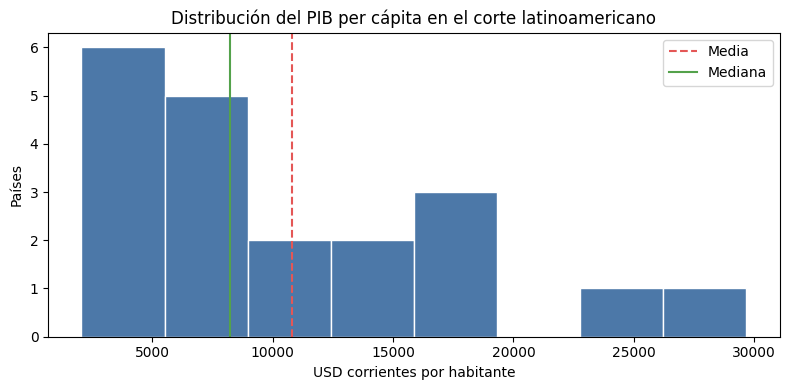

In [25]:
pib_pc = corte_latam["pib_per_capita"].dropna()
print("Asimetría:", round(pib_pc.skew(), 2))
print("Curtosis:", round(pib_pc.kurtosis(), 2))

plt.figure(figsize=(8, 4))
plt.hist(pib_pc, bins=8, color="#4C78A8", edgecolor="white")
# Comparamos media y mediana: una separación grande puede reflejar una distribución asimétrica.
plt.axvline(pib_pc.mean(), color="#E45756", linestyle="--", label="Media")
plt.axvline(pib_pc.median(), color="#54A24B", label="Mediana")
plt.title("Distribución del PIB per cápita en el corte latinoamericano")
plt.xlabel("USD corrientes por habitante")
plt.ylabel("Países")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Cuartiles, boxplot y posibles valores atípicos

El criterio IQR marca valores fuera de `Q1 - 1.5×IQR` y `Q3 + 1.5×IQR`. Son observaciones para revisar, no errores automáticos.

In [26]:
q1 = pib_pc.quantile(0.25)
q3 = pib_pc.quantile(0.75)
# El rango intercuartílico describe el 50 % central de los valores.
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# La regla de 1,5 IQR identifica valores para revisar; no implica que sean errores.
atipicos = corte_latam.loc[
    (corte_latam["pib_per_capita"] < limite_inferior) |
    (corte_latam["pib_per_capita"] > limite_superior),
    ["pais", "pib_per_capita"]
]
print("Límites:", round(limite_inferior, 2), round(limite_superior, 2))
atipicos

Límites: -8902.11 28790.5


,pais,pib_per_capita
931,Guyana,29675.250158


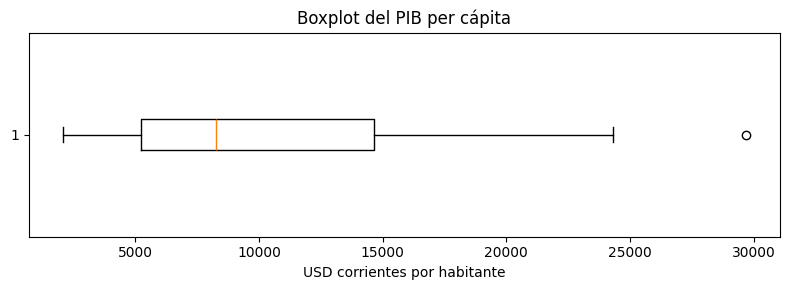

In [ ]:
plt.figure(figsize=(8, 3))
plt.boxplot(pib_pc, orientation="horizontal")
plt.title("Boxplot del PIB per cápita")
plt.xlabel("USD corrientes por habitante")
plt.tight_layout()
plt.show()

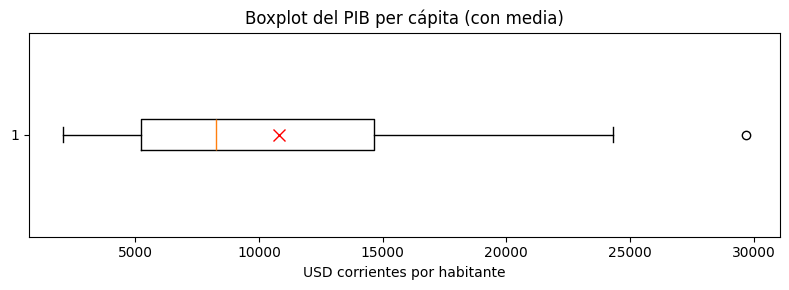

In [ ]:
plt.figure(figsize=(8, 3))
plt.boxplot(pib_pc, vert=False, showmeans=True, meanprops={"marker": "x", "markeredgecolor": "red", "markersize": 8})
plt.title("Boxplot del PIB per cápita (con media)")
plt.xlabel("USD corrientes por habitante")
plt.tight_layout()
plt.show()

### Localizar la fila de un mínimo o máximo

`idxmin()` y `idxmax()` devuelven el índice donde aparece el menor o mayor valor. Después, `.loc[]` recupera las columnas que queremos mostrar. Primero localizamos el menor PIB per cápita; el ejercicio repetirá el patrón con Internet.

In [ ]:
indice_menor_pib = corte_latam["pib_per_capita"].idxmin()
corte_latam.loc[indice_menor_pib, ["pais", "pib_per_capita"]]

,924
pais,Haiti
pib_per_capita,2060.355918


### Pausa práctica: observación extrema

**Tiempo sugerido: 3–5 minutos.** Identifica el país con mayor porcentaje de Internet y muestra país y valor.

In [27]:
# Usa idxmax() y loc[]
indice_mayor_internet = corte_latam["internet"].idxmax()
print(corte_latam.loc[indice_mayor_internet, ["pais", "internet"]])

pais            Chile
internet    95.590243
Name: 1232, dtype: object


### Respuesta sugerida

In [ ]:
indice_mayor = corte_latam["internet"].idxmax()
print(corte_latam.loc[indice_mayor, ["pais", "internet"]])

pais            Chile
internet    95.590243
Name: 1232, dtype: object


## 10. Normalidad: gráfico Q-Q y Shapiro-Wilk

La hipótesis nula de Shapiro-Wilk plantea que la muestra es compatible con una distribución normal. Un p-valor menor que 0.05 aporta evidencia para rechazarla; uno mayor no demuestra normalidad.

La prueba depende del tamaño muestral. Debe acompañarse con gráfico, contexto y propósito del análisis.

**Alcance de la inferencia:** los países disponibles no son una muestra aleatoria simple. Estas pruebas se usan para aprender su lógica y describir compatibilidad con supuestos dentro del corte observado; no autorizan generalizaciones automáticas a otros años, territorios o procesos causales.

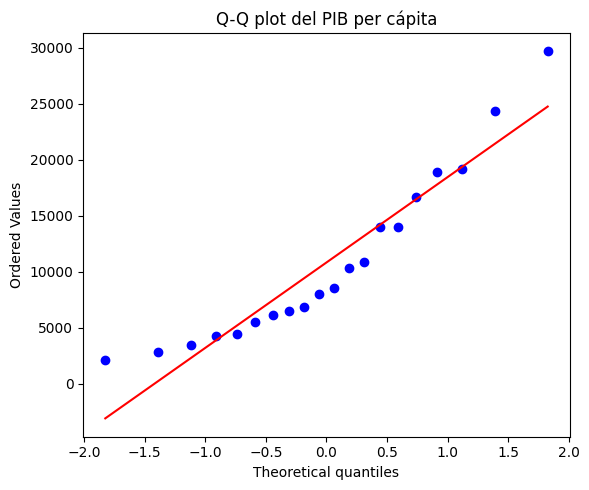

Estadístico: 0.8994
p-valor: 0.0401


In [28]:
plt.figure(figsize=(6, 5))
stats.probplot(pib_pc, dist="norm", plot=plt)
plt.title("Q-Q plot del PIB per cápita")
plt.tight_layout()
plt.show()

estadistico_shapiro, p_shapiro = stats.shapiro(pib_pc)
print("Estadístico:", round(estadistico_shapiro, 4))
print("p-valor:", round(p_shapiro, 4))

Una transformación logarítmica puede reducir la asimetría de magnitudes positivas. No se usa para “obligar” un resultado, sino porque muchas variables económicas se interpretan proporcionalmente.

In [ ]:
log_pib_pc = np.log(pib_pc)
estadistico_log, p_log = stats.shapiro(log_pib_pc)
print("Asimetría original:", round(pib_pc.skew(), 3))
print("Asimetría log:", round(log_pib_pc.skew(), 3))
print("p Shapiro original:", round(p_shapiro, 4))
print("p Shapiro log:", round(p_log, 4))

Asimetría original: 1.055
Asimetría log: -0.121
p Shapiro original: 0.0401
p Shapiro log: 0.9532


### Pausa práctica: normalidad de otra variable

**Tiempo sugerido: 3–5 minutos.** Aplica Shapiro-Wilk a Internet, reporta el p-valor y escribe una interpretación prudente.

In [ ]:
# Completa la prueba
interpretacion = "Escribe aquí"

### Respuesta sugerida

In [ ]:
internet_prueba = corte_latam["internet"].dropna()
estadistico, p_valor = stats.shapiro(internet_prueba)
print("p-valor:", round(p_valor, 4))
interpretacion = "Se rechaza normalidad al 5%." if p_valor < 0.05 else "No se encuentra evidencia suficiente para rechazar normalidad al 5%."
print(interpretacion)

p-valor: 0.3032
No se encuentra evidencia suficiente para rechazar normalidad al 5%.


## 11. Intervalo de confianza para una media

Un intervalo de confianza combina una estimación puntual con su incertidumbre. Aquí estimaremos la media de uso de Internet de los países latinoamericanos observados usando la distribución t.

**Lectura prudente:** estos países no son una muestra aleatoria simple. El intervalo sirve para aprender el procedimiento y resumir este conjunto; no convierte automáticamente el corte disponible en una muestra representativa de todos los países o años posibles.

In [ ]:
internet_intervalo = corte_latam["internet"].dropna()
n_intervalo = len(internet_intervalo)
media_internet = internet_intervalo.mean()
# El error estándar y el valor crítico t se combinan para obtener el margen del intervalo.
error_estandar = stats.sem(internet_intervalo)
# Para un intervalo bilateral del 95 %, el cuantil superior es 0,975.
valor_critico = stats.t.ppf(0.975, df=n_intervalo - 1)
margen_error = valor_critico * error_estandar
limite_inferior = media_internet - margen_error
limite_superior = media_internet + margen_error

print("Países:", n_intervalo)
print("Media:", round(media_internet, 2))
print(f"IC 95%: ({limite_inferior:.2f}, {limite_superior:.2f})")

Países: 21
Media: 77.16
IC 95%: (71.49, 82.82)


El 95% se refiere al comportamiento del procedimiento bajo sus supuestos, no a que exista una probabilidad de 95% de que esta media observada cambie de lugar. Conviene informar siempre tamaño, estimación, intervalo y alcance.

## 12. Relación entre variables: gráfico y correlación

Pearson resume asociación lineal. Spearman resume asociación monotónica mediante rangos y es menos sensible a valores extremos. Ninguna correlación demuestra causalidad.

In [ ]:
pares = corte_latam[["internet", "pib_per_capita", "pais"]].dropna()

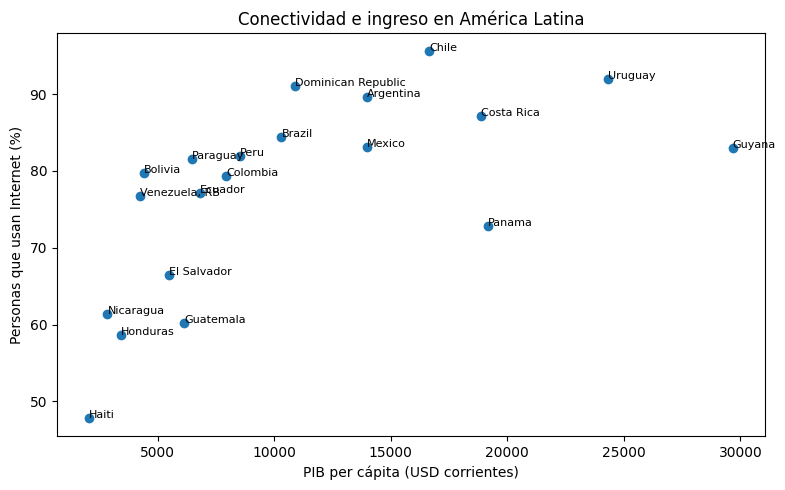

In [ ]:
# Graficamos PIB per cápita e Internet e identificamos cada país.

plt.figure(figsize=(8, 5))

plt.scatter(
    pares["pib_per_capita"],
    pares["internet"]
)

for x, y, pais in zip(
    pares["pib_per_capita"],
    pares["internet"],
    pares["pais"]
):
    plt.text(x, y, pais, fontsize=8)


plt.xlabel("PIB per cápita (USD corrientes)")
plt.ylabel("Personas que usan Internet (%)")
plt.title("Conectividad e ingreso en América Latina")
plt.tight_layout()
plt.show()

In [ ]:
pearson_r, pearson_p = stats.pearsonr(
    pares["pib_per_capita"], pares["internet"]
)
spearman_r, spearman_p = stats.spearmanr(
    pares["pib_per_capita"], pares["internet"]
)
print("Pearson r y p:", round(pearson_r, 3), round(pearson_p, 4))
print("Spearman rho y p:", round(spearman_r, 3), round(spearman_p, 4))

Pearson r y p: 0.612 0.0042
Spearman rho y p: 0.758 0.0001


In [ ]:
# corr utiliza los pares disponibles en cada comparación; el faltante de inflación
# de Venezuela no la excluye de las relaciones entre las otras variables.
matriz_correlacion = corte_latam[variables_numericas].corr(method="spearman")
matriz_correlacion.round(2)

,internet,pib_per_capita,desempleo,inflacion,esperanza_vida,poblacion
internet,1.00,0.76,0.33,0.05,0.48,0.14
pib_per_capita,0.76,1.00,0.40,-0.25,0.60,-0.18
desempleo,0.33,0.40,1.00,0.23,0.17,-0.14
inflacion,0.05,-0.25,0.23,1.00,-0.24,0.39
esperanza_vida,0.48,0.60,0.17,-0.24,1.00,0.03
poblacion,0.14,-0.18,-0.14,0.39,0.03,1.00


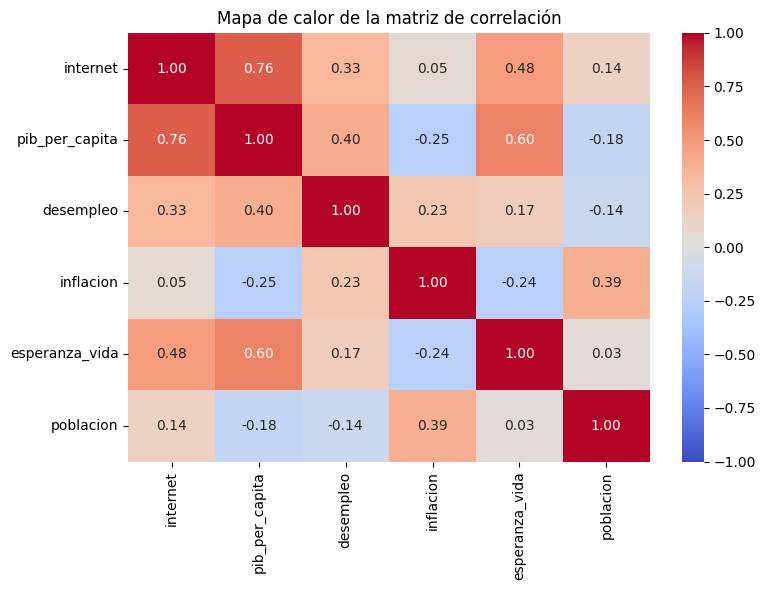

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Mapa de calor de la matriz de correlación')
plt.tight_layout()
plt.show()

### Explorar países con un gráfico interactivo

El gráfico muestra la misma relación, pero permite consultar país, año y valores al acercar el cursor. La interactividad ayuda a identificar observaciones; no cambia la interpretación de la asociación.

In [ ]:
# El cursor identifica el país; el color distingue los grupos de ingreso.
fig_relacion = px.scatter(
    corte_latam.dropna(subset=["pib_per_capita", "internet"]),
    x="pib_per_capita", y="internet", color="nivel_ingreso", hover_name="pais",
    hover_data=["anio"],
    labels={"pib_per_capita": "PIB per cápita (USD corrientes)",
            "internet": "Uso de Internet (%)", "nivel_ingreso": "Nivel de ingreso"},
    title=f"Ingreso y conectividad, {anio_corte}"
)
fig_relacion.show()

### Pausa práctica: interpretar una correlación

**Tiempo sugerido: 3–5 minutos.** Calcula Spearman entre desempleo e Internet y completa una frase que indique dirección, fuerza aproximada y que no implica causalidad.

In [ ]:
# Calcula sobre filas completas
interpretacion_correlacion = "Completa"

### Respuesta sugerida

In [ ]:
datos_corr = corte_latam[["desempleo", "internet"]].dropna()
rho, p_valor = stats.spearmanr(datos_corr["desempleo"], datos_corr["internet"])
print("rho:", round(rho, 3), "p:", round(p_valor, 4))
interpretacion_correlacion = f"La asociación monotónica observada tiene signo {'positivo' if rho > 0 else 'negativo'} y magnitud {abs(rho):.2f}; no establece causalidad."
print(interpretacion_correlacion)

rho: 0.33 p: 0.1442
La asociación monotónica observada tiene signo positivo y magnitud 0.33; no establece causalidad.


## 13. Variables categóricas y chi-cuadrado

La prueba chi-cuadrado de independencia evalúa si dos variables categóricas muestran asociación. Usaremos el corte mundial para tener más observaciones y compararemos nivel de ingreso con una categoría de conectividad.

La categoría `internet_alto` se define solo para el ejercicio como 80% o más. Cambiar el umbral puede cambiar el resultado.

In [ ]:
corte_mundial = panel_paises.loc[panel_paises["anio"].eq(anio_corte)].copy()
# Retiramos economías sin clasificación para comparar grupos definidos.
corte_mundial = corte_mundial[
    corte_mundial["nivel_ingreso"].ne("Not classified")
].copy()
corte_mundial = corte_mundial.dropna(subset=["internet", "nivel_ingreso"]).copy()
# Convertimos el porcentaje en dos categorías para construir la tabla de contingencia.
corte_mundial["categoria_internet"] = np.where(
    corte_mundial["internet"] >= 80,
    "80% o más",
    "Menos de 80%"
)
# Las filas son grupos de ingreso y las columnas son categorías de conectividad.
tabla_contingencia = pd.crosstab(
    corte_mundial["nivel_ingreso"],
    corte_mundial["categoria_internet"]
)
tabla_contingencia

categoria_internet,80% o más,Menos de 80%
nivel_ingreso,,
High income,62,4
Low income,0,19
Lower middle income,6,37
Upper middle income,31,23


In [ ]:
chi2, p_chi2, grados_libertad, esperados = stats.chi2_contingency(
    tabla_contingencia
)
# Los conteos esperados ayudan a revisar si la aproximación de chi-cuadrado es adecuada.
esperados_df = pd.DataFrame(
    esperados,
    index=tabla_contingencia.index,
    columns=tabla_contingencia.columns
)
print("Chi-cuadrado:", round(chi2, 3))
print("Grados de libertad:", grados_libertad)
print("p-valor:", f"{p_chi2:.3e}")
print("Celdas esperadas menores que 5:", (esperados_df < 5).sum().sum())

Chi-cuadrado: 92.814
Grados de libertad: 3
p-valor: 5.444e-20
Celdas esperadas menores que 5: 0


Un p-valor pequeño indica asociación estadística, no su magnitud. Calcularemos V de Cramér entre 0 y 1 como medida descriptiva de fuerza.

In [ ]:
# El tamaño se calcula en la siguiente celda.

In [ ]:
n_chi = tabla_contingencia.values.sum()
minimo_dimension = min(tabla_contingencia.shape) - 1
v_cramer = np.sqrt(chi2 / (n_chi * minimo_dimension))
print("V de Cramér:", round(v_cramer, 3))

V de Cramér: 0.714


### Pausa práctica: interpretar chi-cuadrado

**Tiempo sugerido: 3–5 minutos.** Escribe una conclusión usando el p-valor y V de Cramér. Menciona que el umbral de 80% es una decisión analítica.

In [ ]:
conclusion_chi = "Completa la conclusión"
print(conclusion_chi)

Completa la conclusión


### Respuesta sugerida

In [ ]:
conclusion_chi = f"Con p={p_chi2:.4g} se evalúa la independencia entre nivel de ingreso y la categoría de conectividad. V de Cramér={v_cramer:.2f} describe la magnitud. El resultado depende también del umbral analítico de 80% y no demuestra causalidad."
print(conclusion_chi)

Con p=5.444e-20 se evalúa la independencia entre nivel de ingreso y la categoría de conectividad. V de Cramér=0.71 describe la magnitud. El resultado depende también del umbral analítico de 80% y no demuestra causalidad.


## 14. Comparar dos o más grupos: t, ANOVA y Kruskal-Wallis

Antes del código, identifiquemos la estructura común:

| Elemento | En este ejemplo |
|---|---|
| Variable cuantitativa | porcentaje de personas que usan Internet |
| Variable de agrupación | nivel de ingreso del país |
| Dos grupos | t de Welch |
| Tres o más grupos | ANOVA o Kruskal-Wallis |

### Prueba t de Welch

La prueba t de Welch compara la media de dos grupos sin exigir varianzas iguales. La hipótesis nula plantea igualdad de medias. Como ejemplo pedagógico comparamos conectividad entre países de ingreso alto e ingreso mediano alto.

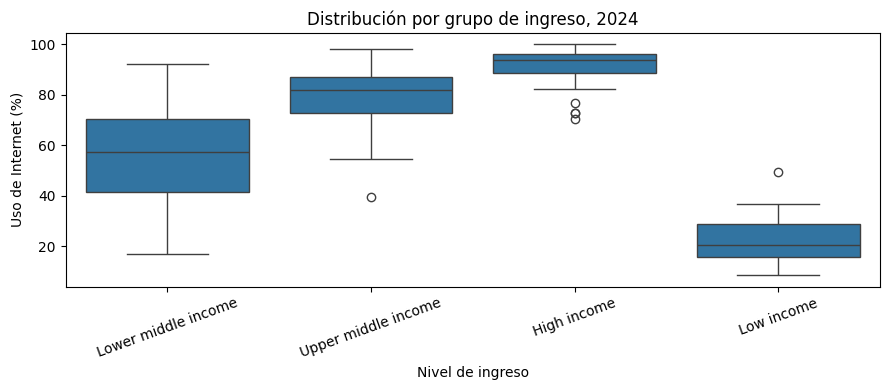

In [ ]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=corte_mundial, x="nivel_ingreso", y="internet")
plt.xlabel("Nivel de ingreso")
plt.ylabel("Uso de Internet (%)")
plt.title(f"Distribución por grupo de ingreso, {anio_corte}")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

La caja permite comparar medianas, dispersión y valores extremos antes de interpretar las pruebas. Diferencias visibles no explican por sí solas su causa.

In [ ]:
internet_ingreso_alto = corte_mundial.loc[
    corte_mundial["nivel_ingreso"].eq("High income"), "internet"
].dropna()
internet_ingreso_medio_alto = corte_mundial.loc[
    corte_mundial["nivel_ingreso"].eq("Upper middle income"), "internet"
].dropna()

# Welch permite comparar las medias sin exigir varianzas iguales entre los grupos.
t_welch, p_welch = stats.ttest_ind(
    internet_ingreso_alto,
    internet_ingreso_medio_alto,
    equal_var=False
)
print("Ingreso alto: n y media =", len(internet_ingreso_alto), round(internet_ingreso_alto.mean(), 2))
print("Ingreso mediano alto: n y media =", len(internet_ingreso_medio_alto), round(internet_ingreso_medio_alto.mean(), 2))
print("t de Welch:", round(t_welch, 3), "p:", f"{p_welch:.3e}")

Ingreso alto: n y media = 66 91.71
Ingreso mediano alto: n y media = 54 79.26
t de Welch: 7.002 p: 6.282e-10


In [ ]:
# Calculamos Hedges' g para medir el tamaño estandarizado
# de la diferencia entre los dos grupos.

n1 = len(internet_ingreso_alto)
n2 = len(internet_ingreso_medio_alto)

media1 = internet_ingreso_alto.mean()
media2 = internet_ingreso_medio_alto.mean()

var1 = internet_ingreso_alto.var(ddof=1)
var2 = internet_ingreso_medio_alto.var(ddof=1)

# Desviación estándar combinada
desviacion_combinada = np.sqrt(
    ((n1 - 1) * var1 + (n2 - 1) * var2)
    / (n1 + n2 - 2)
)

# Cohen's d
d_cohen = (media1 - media2) / desviacion_combinada

# Corrección de Hedges para muestras pequeñas
correccion = 1 - (3 / (4 * (n1 + n2) - 9))

g_hedges = d_cohen * correccion

print("Cohen d:", round(d_cohen, 3))
print("Hedges g:", round(g_hedges, 3))

Cohen d: 1.349
Hedges g: 1.34


### ANOVA de una vía

ANOVA contrasta simultáneamente si las medias de varios grupos son iguales. Un resultado significativo indica que al menos una media difiere, pero no identifica cuál; para eso se necesitarían comparaciones posteriores. Revisaremos además la homogeneidad de dispersión con Levene, sin convertirla en una regla mecánica.

In [ ]:
nombres_anova = []
grupos_anova = []
# Guardamos únicamente grupos con al menos cinco observaciones disponibles.
for nombre_grupo, grupo in corte_mundial.groupby("nivel_ingreso"):
    valores_grupo = grupo["internet"].dropna().to_numpy()
    if len(valores_grupo) >= 5:
        nombres_anova.append(nombre_grupo)
        grupos_anova.append(valores_grupo)

# Esta tabla permite revisar tamaño, media y dispersión antes de probar.
resumen_anova = pd.DataFrame({
    "grupo": nombres_anova,
    "n": [len(valores) for valores in grupos_anova],
    "media": [valores.mean() for valores in grupos_anova],
    "desviacion": [valores.std(ddof=1) for valores in grupos_anova],
})
display(resumen_anova.round(2))

,grupo,n,media,desviacion
0,High income,66,91.71,6.83
1,Low income,19,22.98,10.30
2,Lower middle income,43,56.58,20.17
3,Upper middle income,54,79.26,11.52


In [ ]:
# ANOVA evalúa diferencias entre las medias de los grupos;
# Levene evalúa la igualdad de sus varianzas.

f_anova, p_anova = stats.f_oneway(*grupos_anova)
estadistico_levene, p_levene = stats.levene(*grupos_anova, center="median")
print("ANOVA F:", round(f_anova, 3), "p:", f"{p_anova:.3e}")
print("Levene:", round(estadistico_levene, 3), "p:", f"{p_levene:.3e}")

ANOVA F: 172.186 p: 2.192e-52
Levene: 19.295 p: 7.051e-11


### Alternativa no paramétrica

Kruskal-Wallis compara rangos cuando el análisis no se apoya en normalidad. Usaremos los mismos grupos que acabamos de preparar. Tampoco identifica por sí solo cuáles pares difieren. Elegir entre ANOVA y Kruskal-Wallis depende de la pregunta, la escala, el diseño y los supuestos; no solo de buscar el p-valor más pequeño.

In [ ]:
h_kruskal, p_kruskal = stats.kruskal(*grupos_anova)
print("Kruskal-Wallis H:", round(h_kruskal, 3))
print("p-valor:", f"{p_kruskal:.3e}")

Kruskal-Wallis H: 120.003
p-valor: 7.705e-26


### Pausa práctica: interpretar una comparación de grupos

**Tiempo sugerido: 3–5 minutos.** Completa una conclusión de ANOVA que mencione el p-valor, lo que sí permite afirmar y lo que todavía requeriría una prueba posterior.

In [ ]:
conclusion_anova = "Completa la conclusión"
print(conclusion_anova)

Completa la conclusión


### Respuesta sugerida

In [ ]:
conclusion_anova = f"El ANOVA obtuvo p={p_anova:.4g}. Si es menor que 0.05, aporta evidencia de que no todas las medias de conectividad son iguales; no señala por sí solo qué pares difieren y requeriría comparaciones posteriores y revisión de supuestos."
print(conclusion_anova)

El ANOVA obtuvo p=2.192e-52. Si es menor que 0.05, aporta evidencia de que no todas las medias de conectividad son iguales; no señala por sí solo qué pares difieren y requeriría comparaciones posteriores y revisión de supuestos.


## 15. Evolución temporal

Una serie muestra cambios dentro de una unidad. No debemos confundir la comparación entre países de 2024 con la evolución de un país entre 2018 y 2024.

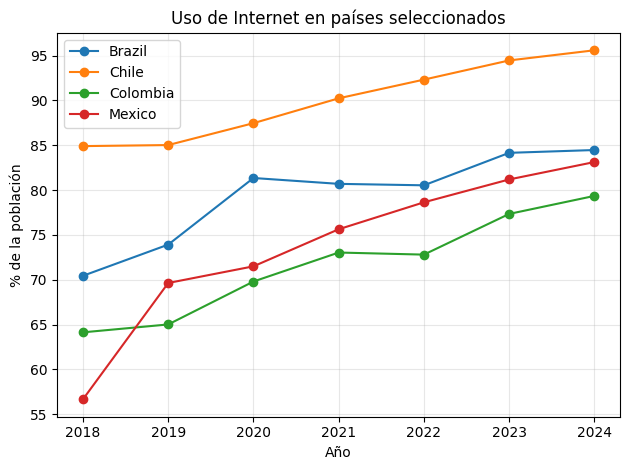

In [ ]:
seleccion_tendencia = panel_latam[
    panel_latam["codigo_pais"].isin(["COL", "MEX", "CHL", "BRA"])
]

# Dibujamos una línea independiente por país.
for codigo, grupo in seleccion_tendencia.groupby("codigo_pais"):
    grupo = grupo.sort_values("anio")
    plt.plot(
        grupo["anio"], grupo["internet"],
        marker="o", label=grupo["pais"].iloc[0]
    )
plt.title("Uso de Internet en países seleccionados")
plt.xlabel("Año")
plt.ylabel("% de la población")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
fig_tendencia = px.line(seleccion_tendencia.sort_values(["pais", "anio"]), x="anio", y="internet", color="pais", markers=True, labels={"anio": "Año", "internet": "Uso de Internet (%)", "pais": "País"}, title="Evolución de la conectividad")
fig_tendencia.show()

### Calcular un cambio entre dos momentos

Ordenamos un país por año, retiramos faltantes y restamos el primer valor al último. Lo demostramos con México; la pausa práctica repetirá exactamente el patrón con Colombia.

In [ ]:
mexico = panel_latam[
    panel_latam["codigo_pais"].eq("MEX")
].sort_values("anio")
serie_mexico = mexico["internet"].dropna()
cambio_mexico = serie_mexico.iloc[-1] - serie_mexico.iloc[0]
print("Cambio en México:", round(cambio_mexico, 2), "puntos porcentuales")

Cambio en México: 26.46 puntos porcentuales


### Pausa práctica: cambio temporal

**Tiempo sugerido: 3–5 minutos.** Calcula el cambio en puntos porcentuales de Internet en Colombia entre la primera y última observación disponible.

In [ ]:
# Ordena Colombia y resta último menos primero

### Respuesta sugerida

In [ ]:
colombia = panel_latam[panel_latam["codigo_pais"].eq("COL")].sort_values("anio")
serie_colombia = colombia["internet"].dropna()
cambio_pp = serie_colombia.iloc[-1] - serie_colombia.iloc[0]
print("Cambio:", round(cambio_pp, 2), "puntos porcentuales")

Cambio: 15.22 puntos porcentuales


## 16. Representación geoespacial de los indicadores

Pasamos de comparar valores y tendencias a ubicarlos en un mapa. Las coordenadas de las fichas del Banco Mundial corresponden a puntos asociados a las capitales: el indicador sigue representando al país, no a la ciudad ni a un domicilio.

Usaremos el mismo año del análisis y un punto por país. Esto permite explorar la localización de los valores, sin inferir relaciones espaciales causales.

In [ ]:
columnas_mapa = ["codigo_pais", "pais", "anio", "internet", "pib_per_capita", "capitalCity", "longitude", "latitude"]
datos_mapa = corte_latam[columnas_mapa].copy()
# Verificamos los rangos geográficos antes de construir las geometrías.
coordenadas_validas = datos_mapa["longitude"].between(-180, 180) & datos_mapa["latitude"].between(-90, 90)
print("Países sin coordenadas utilizables:", (~coordenadas_validas).sum())
# Dibujamos solo puntos con coordenadas válidas y el indicador disponible.
datos_mapa = datos_mapa.loc[coordenadas_validas].dropna(subset=["internet"]).copy()
if datos_mapa.empty:
    raise ValueError("No hay coordenadas e indicadores disponibles para el mapa. Actualiza los metadatos del Banco Mundial.")
datos_mapa.head()

Países sin coordenadas utilizables: 0


,codigo_pais,pais,anio,internet,pib_per_capita,capitalCity,longitude,latitude
42,VEN,"Venezuela, RB",2024,76.678902,4244.457231,Caracas,-69.8371,9.08165
63,URY,Uruguay,2024,91.991090,24308.495496,Montevideo,-56.0675,-34.89410
434,PER,Peru,2024,81.957060,8526.296657,Lima,-77.0465,-12.09310
441,PRY,Paraguay,2024,81.578068,6456.607231,Asuncion,-57.6362,-25.30050
455,PAN,Panama,2024,72.771500,19161.218843,Panama City,-79.5188,8.99427


### De tabla a geometría con GeoPandas

`points_from_xy()` recibe longitud y latitud, en ese orden. `EPSG:4326` identifica el sistema geográfico de coordenadas usado. El resultado conserva las columnas y añade una geometría de punto.

In [ ]:
# points_from_xy recibe longitud (x) y latitud (y); EPSG:4326 expresa ambas en grados.
puntos_paises = gpd.GeoDataFrame(datos_mapa, geometry=gpd.points_from_xy(datos_mapa["longitude"], datos_mapa["latitude"]), crs="EPSG:4326")
print("Sistema de referencia:", puntos_paises.crs)
puntos_paises[["pais", "internet", "geometry"]].head()

Sistema de referencia: EPSG:4326


,pais,internet,geometry
42,"Venezuela, RB",76.678902,POINT (-69.8371 9.08165)
63,Uruguay,91.991090,POINT (-56.0675 -34.8941)
434,Peru,81.957060,POINT (-77.0465 -12.0931)
441,Paraguay,81.578068,POINT (-57.6362 -25.3005)
455,Panama,72.771500,POINT (-79.5188 8.99427)


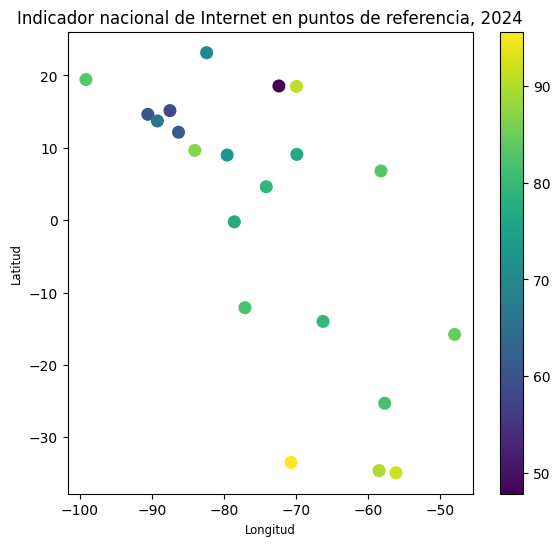

In [ ]:
ax = puntos_paises.plot(column="internet", cmap="viridis", legend=True, markersize=70, figsize=(7, 6))
ax.set_title(f"Indicador nacional de Internet en puntos de referencia, {anio_corte}")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.show()

### Mapa interactivo con Folium

Folium recibe cada ubicación como **latitud, longitud**. Cada círculo permite consultar el país y su indicador. Usamos una escala fija de 0 a 100 % para comparar colores.

In [29]:
mapa = folium.Map(location=[-10, -65], zoom_start=3, tiles="OpenStreetMap")
# Una escala fija de 0 a 100 permite interpretar el mismo color en todos los países.
escala_internet = linear.YlGnBu_09.scale(0, 100)
escala_internet.caption = f"Personas que usan Internet (%), {anio_corte}"
# Cada fila aporta un marcador; Folium recibe latitud antes de longitud.
for _, fila in datos_mapa.iterrows():
    # escape evita que caracteres del nombre se interpreten como etiquetas HTML.
    etiqueta = f"{escape(str(fila['pais']))}: {fila['internet']:.1f}% ({int(fila['anio'])})"
    folium.CircleMarker(
        location=[fila["latitude"], fila["longitude"]], radius=7,
        color=escala_internet(fila["internet"]), fill=True, fill_opacity=0.8,
        tooltip=etiqueta, popup=etiqueta
    ).add_to(mapa)
escala_internet.add_to(mapa)
mapa

NameError: name 'datos_mapa' is not defined

### Pausa práctica: interpretar un mapa

Selecciona los tres países con mayor porcentaje de Internet de la tabla utilizada en el mapa. Localízalos y escribe una observación que distinga el indicador nacional del punto donde se representa.

In [ ]:
# Desarrolla el ejercicio aquí.

### Respuesta sugerida

In [ ]:
mayores_internet = datos_mapa.sort_values("internet", ascending=False).head(3)
display(mayores_internet[["pais", "anio", "internet", "capitalCity"]])
print("Los símbolos representan indicadores nacionales y están localizados mediante coordenadas de referencia de las capitales; no describen solo a esas ciudades.")

,pais,anio,internet,capitalCity
1232,Chile,2024,95.590243,Santiago
63,Uruguay,2024,91.991090,Montevideo
1120,Dominican Republic,2024,91.002245,Santo Domingo


Los símbolos representan indicadores nacionales y están localizados mediante coordenadas de referencia de las capitales; no describen solo a esas ciudades.


### Calcular la distancia entre dos capitales

Usamos los puntos del GeoDataFrame para comparar Bogotá y Quito. Sus coordenadas están en grados: una distancia directa entre geometrías en `EPSG:4326` no entrega kilómetros. Con `Geod` calculamos la **distancia geodésica sobre el elipsoide WGS84** y convertimos metros a kilómetros. Es la separación sobre la superficie terrestre, no una distancia por carretera.

Las coordenadas provienen de los metadatos del Banco Mundial; trabajamos con sus puntos de referencia de las capitales. [Documentación de Geod](https://pyproj4.github.io/pyproj/stable/api/geod.html).

In [ ]:
geodesia = Geod(ellps="WGS84")
# El código del país como índice permite seleccionar los dos puntos con loc.
capitales = puntos_paises.set_index("codigo_pais")

origen = capitales.loc["COL"]
destino = capitales.loc["ECU"]
# inv devuelve dos azimuts y la distancia: aquí conservamos solo la distancia.
_, _, distancia_metros = geodesia.inv(
    origen.geometry.x, origen.geometry.y,
    destino.geometry.x, destino.geometry.y
)
# Geod entrega metros; dividimos entre mil para comunicar kilómetros.
distancia_km = distancia_metros / 1000
print(f"{origen['capitalCity']} → {destino['capitalCity']}: {distancia_km:,.1f} km")
print(f"Internet en Colombia: {origen['internet']:.1f} %")
print(f"Internet en Ecuador: {destino['internet']:.1f} %")
print(f"Diferencia Ecuador − Colombia: {destino['internet'] - origen['internet']:+.1f} puntos porcentuales")

Bogota → Quito: 728.3 km
Internet en Colombia: 79.3 %
Internet en Ecuador: 77.2 %
Diferencia Ecuador − Colombia: -2.2 puntos porcentuales


### De dos puntos a una comparación entre países

Repetimos el cálculo desde el mismo origen hacia las demás capitales disponibles. Conservamos el indicador de Internet del mismo año para construir una tabla y explorar dos preguntas: ¿cuáles son las capitales más cercanas a Bogotá?, ¿qué valores de conectividad nacional tienen los países a distintas distancias?

In [ ]:
filas_distancias = []
for codigo, fila in capitales.iterrows():
    # Omitimos el origen para no incluir la distancia de Bogotá a sí misma.
    if codigo == "COL":
        continue
    # Conservamos Bogotá como origen y cambiamos el destino en cada iteración.
    _, _, metros = geodesia.inv(
        origen.geometry.x, origen.geometry.y,
        fila.geometry.x, fila.geometry.y
    )
    # Unimos la distancia entre capitales con el indicador nacional del mismo año.
    filas_distancias.append({
        "codigo_pais": codigo, "pais": fila["pais"], "capital": fila["capitalCity"],
        "distancia_km": metros / 1000, "internet": fila["internet"],
        "diferencia_internet_pp": fila["internet"] - origen["internet"]
    })

# Ordenamos de menor a mayor distancia antes de seleccionar las cinco más cercanas.
distancias_capitales = pd.DataFrame(filas_distancias).sort_values("distancia_km")
display(distancias_capitales.round(1))

,codigo_pais,pais,capital,distancia_km,internet,diferencia_internet_pp
0,VEN,"Venezuela, RB",Caracas,681.6,76.7,-2.7
12,ECU,Ecuador,Quito,728.3,77.2,-2.2
4,PAN,Panama,Panama City,772.1,72.8,-6.6
15,CRI,Costa Rica,San Jose,1229.1,87.2,7.8
8,HTI,Haiti,Port-au-Prince,1552.7,47.9,-31.5
5,NIC,Nicaragua,Managua,1579.6,61.4,-17.9
13,DOM,Dominican Republic,Santo Domingo,1600.6,91.0,11.7
9,GUY,Guyana,Georgetown,1780.7,83.0,3.7
7,HND,Honduras,Tegucigalpa,1871.7,58.6,-20.7
2,PER,Peru,Lima,1876.0,82.0,2.6


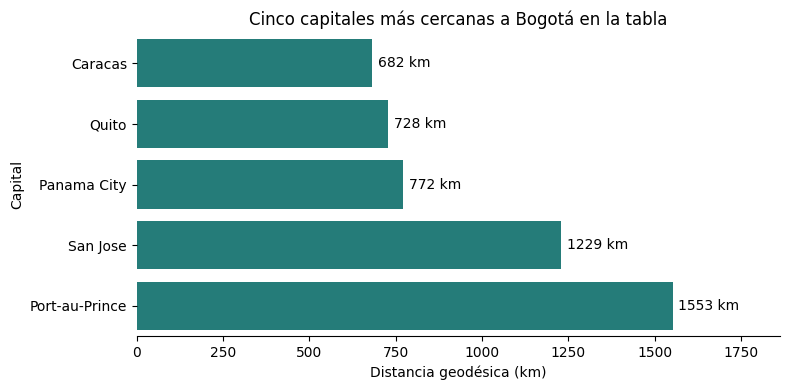

In [ ]:
# head(5) toma las primeras cinco filas de la tabla ya ordenada por distancia.
cercanas = distancias_capitales.head(5)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=cercanas, x="distancia_km", y="capital", color="#168b87", ax=ax)
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f km", padding=4)
ax.set(title="Cinco capitales más cercanas a Bogotá en la tabla",
       xlabel="Distancia geodésica (km)", ylabel="Capital")
ax.margins(x=0.2)
ax.grid(axis="y", visible=False)
sns.despine(left=True)
plt.tight_layout()
plt.show()

# La dispersión combina distancia e Internet; el cursor permite identificar cada país.
fig_distancias = px.scatter(
    distancias_capitales, x="distancia_km", y="internet", hover_name="pais",
    hover_data={"capital": True, "distancia_km": ":.1f", "internet": ":.1f",
                "diferencia_internet_pp": ":+.1f"},
    labels={"distancia_km": "Distancia desde Bogotá (km)",
            "internet": "Personas que usan Internet (%)", "capital": "Capital",
            "diferencia_internet_pp": "Diferencia con Colombia (pp)"},
    title=f"Distancia entre capitales y conectividad nacional, {anio_corte}",
    template="plotly_white"
)
fig_distancias.update_traces(marker=dict(size=11, color="#168b87", line=dict(width=1, color="white")))
# La línea de Colombia es una referencia de conectividad, no una tendencia ajustada.
fig_distancias.add_hline(y=origen["internet"], line_dash="dot", line_color="#c35b38",
                        annotation_text="Colombia")
fig_distancias.update_layout(height=440)
fig_distancias.show()

**Lectura del gráfico:** cada punto combina la distancia entre dos capitales con un indicador de todo el país. La línea horizontal representa la conectividad nacional de Colombia. Esta comparación permite formular preguntas; no demuestra que la distancia explique las diferencias de Internet.

### Pausa práctica: cambiar los dos puntos

Calcula la distancia entre Quito (`ECU`) y Lima (`PER`) usando sus geometrías. Muestra el resultado en kilómetros y la diferencia del porcentaje de Internet de Perú menos Ecuador. Explica por qué ese resultado no informa cuánto dura un viaje entre las ciudades.

In [ ]:
# Desarrolla el ejercicio aquí.

### Respuesta sugerida

In [ ]:
quito = capitales.loc["ECU"]
lima = capitales.loc["PER"]
# Reutilizamos el método cambiando únicamente los dos países del ejemplo.
_, _, metros_quito_lima = geodesia.inv(
    quito.geometry.x, quito.geometry.y, lima.geometry.x, lima.geometry.y
)
print(f"Quito → Lima: {metros_quito_lima / 1000:,.1f} km")
print(f"Internet, Perú − Ecuador: {lima['internet'] - quito['internet']:+.1f} puntos porcentuales")
print("La distancia geodésica no incluye rutas, relieve, tráfico ni medio de transporte.")

Quito → Lima: 1,322.1 km
Internet, Perú − Ecuador: +4.8 puntos porcentuales
La distancia geodésica no incluye rutas, relieve, tráfico ni medio de transporte.


## 17. Del hallazgo a una nueva pregunta

Un EDA bien cerrado registra:

1. qué observación o patrón apareció;
2. qué definición y periodo se usaron;
3. qué explicaciones alternativas existen;
4. qué análisis permitiría profundizar;
5. qué no puede concluirse.

In [ ]:
hallazgo_eda = {
    "patron": "Internet y PIB per cápita muestran asociación en el corte.",
    "unidad": "país",
    "periodo": "año 2024",
    "siguiente_paso": "contrastar el patrón con otras fuentes y periodos",
    "limite": "la asociación transversal no demuestra causalidad",
}
print(hallazgo_eda)

{'patron': 'Internet y PIB per cápita muestran asociación en el corte.', 'unidad': 'país', 'periodo': 'año 2024', 'siguiente_paso': 'contrastar el patrón con otras fuentes y periodos', 'limite': 'la asociación transversal no demuestra causalidad'}


## Cierre

El EDA integró cobertura, medidas de tendencia y dispersión, asimetría, atípicos, normalidad, intervalos de confianza, correlación, chi-cuadrado, pruebas t, ANOVA, Kruskal-Wallis y evolución temporal. También representamos estos indicadores mediante gráficos interactivos y puntos geográficos, calculamos distancias entre capitales y las relacionamos visualmente con indicadores nacionales.